# Detekcja Phishingu - Regresja Logistyczna

Ten notebook zawiera implementację i analizę modelu regresji logistycznej do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
import sys
sys.path.append('..')

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle
import importlib
import os
import matplotlib.patches as mpatches

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV, validation_curve, learning_curve, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, roc_curve)
from utils.feature_names import get_readable_name
from utils.resource_monitor import ResourceMonitor

from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Circle

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

import os
PLOTS_DIR = "../static/plots/logistic_regression"
MODELS_DIR = "../models/logistic_regression"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych


In [2]:
df_full = pd.read_csv('../data/dataset_full.csv')
df_optimized = pd.read_csv('../data/dataset_optimized.csv')

datasets = {
    'Pełny zbiór': df_full,
    'Zoptymalizowany zbiór': df_optimized
}

print("="*80)
print("DANE ZAŁADOWANE - PORÓWNANIE ZBIORÓW")
print("="*80)

for name, df in datasets.items():
    print(f"\n{name}:")
    print(f"  • Rozmiar zbioru: {df.shape}")
    print(f"  • Liczba cech: {df.shape[1]-1}")

    label_counts = df['phishing'].value_counts()
    print(f"  • Rozkład etykiet:")
    print(f"    - Brak phishingu: {label_counts[0]:,} ({label_counts[0]/len(df)*100:.1f}%)")
    print(f"    - Phishing: {label_counts[1]:,} ({label_counts[1]/len(df)*100:.1f}%)")
    print(f"  • Brakujące wartości: {df.isnull().sum().sum()}")
    print(f"  • Duplikaty: {df.duplicated().sum()}")

print("\n" + "="*80)

DANE ZAŁADOWANE - PORÓWNANIE ZBIORÓW

Pełny zbiór:
  • Rozmiar zbioru: (88647, 112)
  • Liczba cech: 111
  • Rozkład etykiet:
    - Brak phishingu: 58,000 (65.4%)
    - Phishing: 30,647 (34.6%)
  • Brakujące wartości: 0
  • Duplikaty: 1438

Zoptymalizowany zbiór:
  • Rozmiar zbioru: (87209, 75)
  • Liczba cech: 74
  • Rozkład etykiet:
    - Brak phishingu: 56,712 (65.0%)
    - Phishing: 30,497 (35.0%)
  • Brakujące wartości: 0
  • Duplikaty: 13



## 3. Przygotowanie cech i etykiet


In [3]:
data_splits = {}

for name, df in datasets.items():
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

    data_splits[name] = {
        'X': X,
        'y': y,
        'feature_count': X.shape[1]
    }

    print(f"\n{name}:")
    print(f"  • Liczba cech: {X.shape[1]}")
    print(f"  • Rozkład etykiet:")
    for label, count in y.value_counts().items():
        percentage = count / len(y) * 100
        label_name = "Brak Phisingu" if label == 0 else "Phishing"
        print(f"    {label} ({label_name}): {count:,} ({percentage:.1f}%)")


Pełny zbiór:
  • Liczba cech: 111
  • Rozkład etykiet:
    0 (Brak Phisingu): 58,000 (65.4%)
    1 (Phishing): 30,647 (34.6%)

Zoptymalizowany zbiór:
  • Liczba cech: 74
  • Rozkład etykiet:
    0 (Brak Phisingu): 56,712 (65.0%)
    1 (Phishing): 30,497 (35.0%)


## 4. Podział danych i standaryzacja


In [4]:
train_test_data = {}

for name, data in data_splits.items():
    X = data['X']
    y = data['y']

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    train_test_data[name] = {
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'X_train_scaled': X_train_scaled,
        'X_test_scaled': X_test_scaled,
        'scaler': scaler
    }

    print(f"\n{name}:")
    print(f"  • Zbiór uczący: {X_train.shape[0]:,} próbek ({X_train.shape[0]/len(X)*100:.1f}%)")
    print(f"  • Zbiór testowy: {X_test.shape[0]:,} próbek ({X_test.shape[0]/len(X)*100:.1f}%)")

    train_counts = y_train.value_counts()
    print(f"  • Rozkład klas (zbiór uczący):")
    print(f"    - Brak phishingu: {train_counts[0]:,} ({train_counts[0]/len(y_train)*100:.1f}%)")
    print(f"    - Phishing: {train_counts[1]:,} ({train_counts[1]/len(y_train)*100:.1f}%)")

    print(f"  • Statystyki przeskalowanych cech:")
    print(f"    - Średnia: {X_train_scaled.mean():.6f}")
    print(f"    - Odchylenie standardowe: {X_train_scaled.std():.6f}")


Pełny zbiór:
  • Zbiór uczący: 70,917 próbek (80.0%)
  • Zbiór testowy: 17,730 próbek (20.0%)
  • Rozkład klas (zbiór uczący):
    - Brak phishingu: 46,400 (65.4%)
    - Phishing: 24,517 (34.6%)
  • Statystyki przeskalowanych cech:
    - Średnia: 0.000000
    - Odchylenie standardowe: 0.939618

Zoptymalizowany zbiór:
  • Zbiór uczący: 69,767 próbek (80.0%)
  • Zbiór testowy: 17,442 próbek (20.0%)
  • Rozkład klas (zbiór uczący):
    - Brak phishingu: 45,369 (65.0%)
    - Phishing: 24,398 (35.0%)
  • Statystyki przeskalowanych cech:
    - Średnia: -0.000000
    - Odchylenie standardowe: 1.000000

Zoptymalizowany zbiór:
  • Zbiór uczący: 69,767 próbek (80.0%)
  • Zbiór testowy: 17,442 próbek (20.0%)
  • Rozkład klas (zbiór uczący):
    - Brak phishingu: 45,369 (65.0%)
    - Phishing: 24,398 (35.0%)
  • Statystyki przeskalowanych cech:
    - Średnia: -0.000000
    - Odchylenie standardowe: 1.000000


## 5. Optymalizacja hiperparametrów i trening modelu


In [5]:
param_grids = [
    {
        'name': 'Optymalizacja parametru C (solver=liblinear)',
        'params': {
            'C': [0.01, 0.1, 1, 10, 100],
            'solver': ['liblinear'],
            'max_iter': [1000]
        }
    },
    {
        'name': 'Optymalizacja parametru C (solver=lbfgs)',
        'params': {
            'C': [0.1, 1, 10],
            'solver': ['lbfgs'],
            'max_iter': [1000, 2000]
        }
    },
    {
        'name': 'Optymalizacja parametru C (solver=saga)',
        'params': {
            'C': [0.1, 1, 10],
            'solver': ['saga'],
            'max_iter': [1000, 2000]
        }
    }
]

trained_models = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"UCZENIE MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']

    best_overall_score = 0
    best_overall_model = None
    best_overall_params = None
    best_config_name = ""

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']

        combinations = (len(param_grid['C']) *
                       len(param_grid['solver']) *
                       len(param_grid['max_iter']))

        print(f"\nKonfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Testowanie {combinations} kombinacji parametrów...")

        config_start_time = time.time()

        grid_search = GridSearchCV(
            LogisticRegression(random_state=42, n_jobs=-1),
            param_grid,
            cv=5,
            scoring='roc_auc',
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(X_train_scaled, y_train)

        config_time = time.time() - config_start_time

        print(f"  • Najlepszy wynik ROC-AUC: {grid_search.best_score_:.4f}")
        print(f"  • Czas: {config_time:.2f}s")

        if grid_search.best_score_ > best_overall_score:
            best_overall_score = grid_search.best_score_
            best_overall_model = grid_search.best_estimator_
            best_overall_params = grid_search.best_params_
            best_config_name = config_name

    total_time = time.time() - start_time

    trained_models[dataset_name] = {
        'params': best_overall_params,
        'cv_score': best_overall_score,
        'config_name': best_config_name,
        'optimization_time': total_time
    }

    print(f"\n{'-'*80}")
    print(f"WYNIKI OPTYMALIZACJI - {dataset_name}:")
    print(f"  • Czas optymalizacji: {total_time:.2f}s ({total_time/60:.1f} min)")
    print(f"  • Najlepszy wynik CV ROC-AUC: {best_overall_score:.4f}")
    print(f"  • Najlepsza konfiguracja: {best_config_name}")
    print(f"  • Najlepsze parametry: {best_overall_params}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW OPTYMALIZACJI")
print(f"{'='*80}")
for name, results in trained_models.items():
    print(f"\n{name}:")
    print(f"  • CV ROC-AUC: {results['cv_score']:.4f}")
    print(f"  • Czas optymalizacji: {results['optimization_time']:.2f}s")


UCZENIE MODELU - PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja parametru C (solver=liblinear)
Testowanie 5 kombinacji parametrów...
  • Najlepszy wynik ROC-AUC: 0.9793
  • Czas: 167.21s

Konfiguracja 2/3: Optymalizacja parametru C (solver=lbfgs)
Testowanie 6 kombinacji parametrów...
  • Najlepszy wynik ROC-AUC: 0.9793
  • Czas: 167.21s

Konfiguracja 2/3: Optymalizacja parametru C (solver=lbfgs)
Testowanie 6 kombinacji parametrów...
  • Najlepszy wynik ROC-AUC: 0.9793
  • Czas: 27.45s

Konfiguracja 3/3: Optymalizacja parametru C (solver=saga)
Testowanie 6 kombinacji parametrów...
  • Najlepszy wynik ROC-AUC: 0.9793
  • Czas: 27.45s

Konfiguracja 3/3: Optymalizacja parametru C (solver=saga)
Testowanie 6 kombinacji parametrów...
  • Najlepszy wynik ROC-AUC: 0.9792
  • Czas: 1545.16s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Pełny zbiór:
  • Czas optymalizacji: 1739.84s (29.0 min)
  • Najlepszy wynik CV ROC-AUC: 0.9793
  • Najl

## 5.1. Monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
resource_stats = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"TRENING I MONITOROWANIE ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']
    best_params = trained_models[dataset_name]['params']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train_scaled.shape[0]:,} próbek, {X_train_scaled.shape[1]} cech")
    print(f"Parametry modelu: {best_params}")

    monitor = ResourceMonitor(interval=0.1, debug=False)
    monitor.start()

    model = LogisticRegression(**best_params, random_state=42, n_jobs=-1)

    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    training_time = time.time() - start_time

    monitor.stop()

    stats = monitor.get_stats()

    trained_models[dataset_name]['model'] = model
    trained_models[dataset_name]['training_time'] = training_time

    resource_stats[dataset_name] = {
        'monitor': monitor,
        'stats': stats,
        'training_time': training_time
    }

    if stats:
        print(f"\nWYNIKI MONITOROWANIA:")
        print(f"  • Czas treningu: {training_time:.2f}s")
        print(f"  • Liczba próbek monitorowania: {stats['samples']}")
        print(f"  • CPU:")
        print(f"    - Min: {stats['cpu']['min']:.1f}%")
        print(f"    - Max: {stats['cpu']['max']:.1f}%")
        print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
        print(f"  • RAM:")
        print(f"    - Min: {stats['ram']['min']:.2f} GB")
        print(f"    - Max: {stats['ram']['max']:.2f} GB")
        print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")

print(f"\n{'='*80}")
print("TRENOWANIE I MONITOROWANIE ZAKOŃCZONE")
print(f"{'='*80}")


TRENING I MONITOROWANIE ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 70,917 próbek, 111 cech
Parametry modelu: {'C': 1, 'max_iter': 1000, 'solver': 'lbfgs'}

WYNIKI MONITOROWANIA:
  • Czas treningu: 2.94s
  • Liczba próbek monitorowania: 27
  • CPU:
    - Min: 0.0%
    - Max: 9.5%
    - Średnia: 0.9%
  • RAM:
    - Min: 0.39 GB
    - Max: 0.92 GB
    - Średnia: 0.79 GB

TRENING I MONITOROWANIE ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 69,767 próbek, 74 cech
Parametry modelu: {'C': 10, 'max_iter': 1000, 'solver': 'liblinear'}

WYNIKI MONITOROWANIA:
  • Czas treningu: 5.95s
  • Liczba próbek monitorowania: 54
  • CPU:
    - Min: 0.0%
    - Max: 9.4%
    - Średnia: 6.8%
  • RAM:
    - Min: 0.78 GB
    - Max: 0.90 GB
    - Średnia: 0.90 GB

TRENOWANIE I MONITOROWANIE ZAKOŃCZONE


## 5.2. Wizualizacja wykorzystania zasobów systemowych


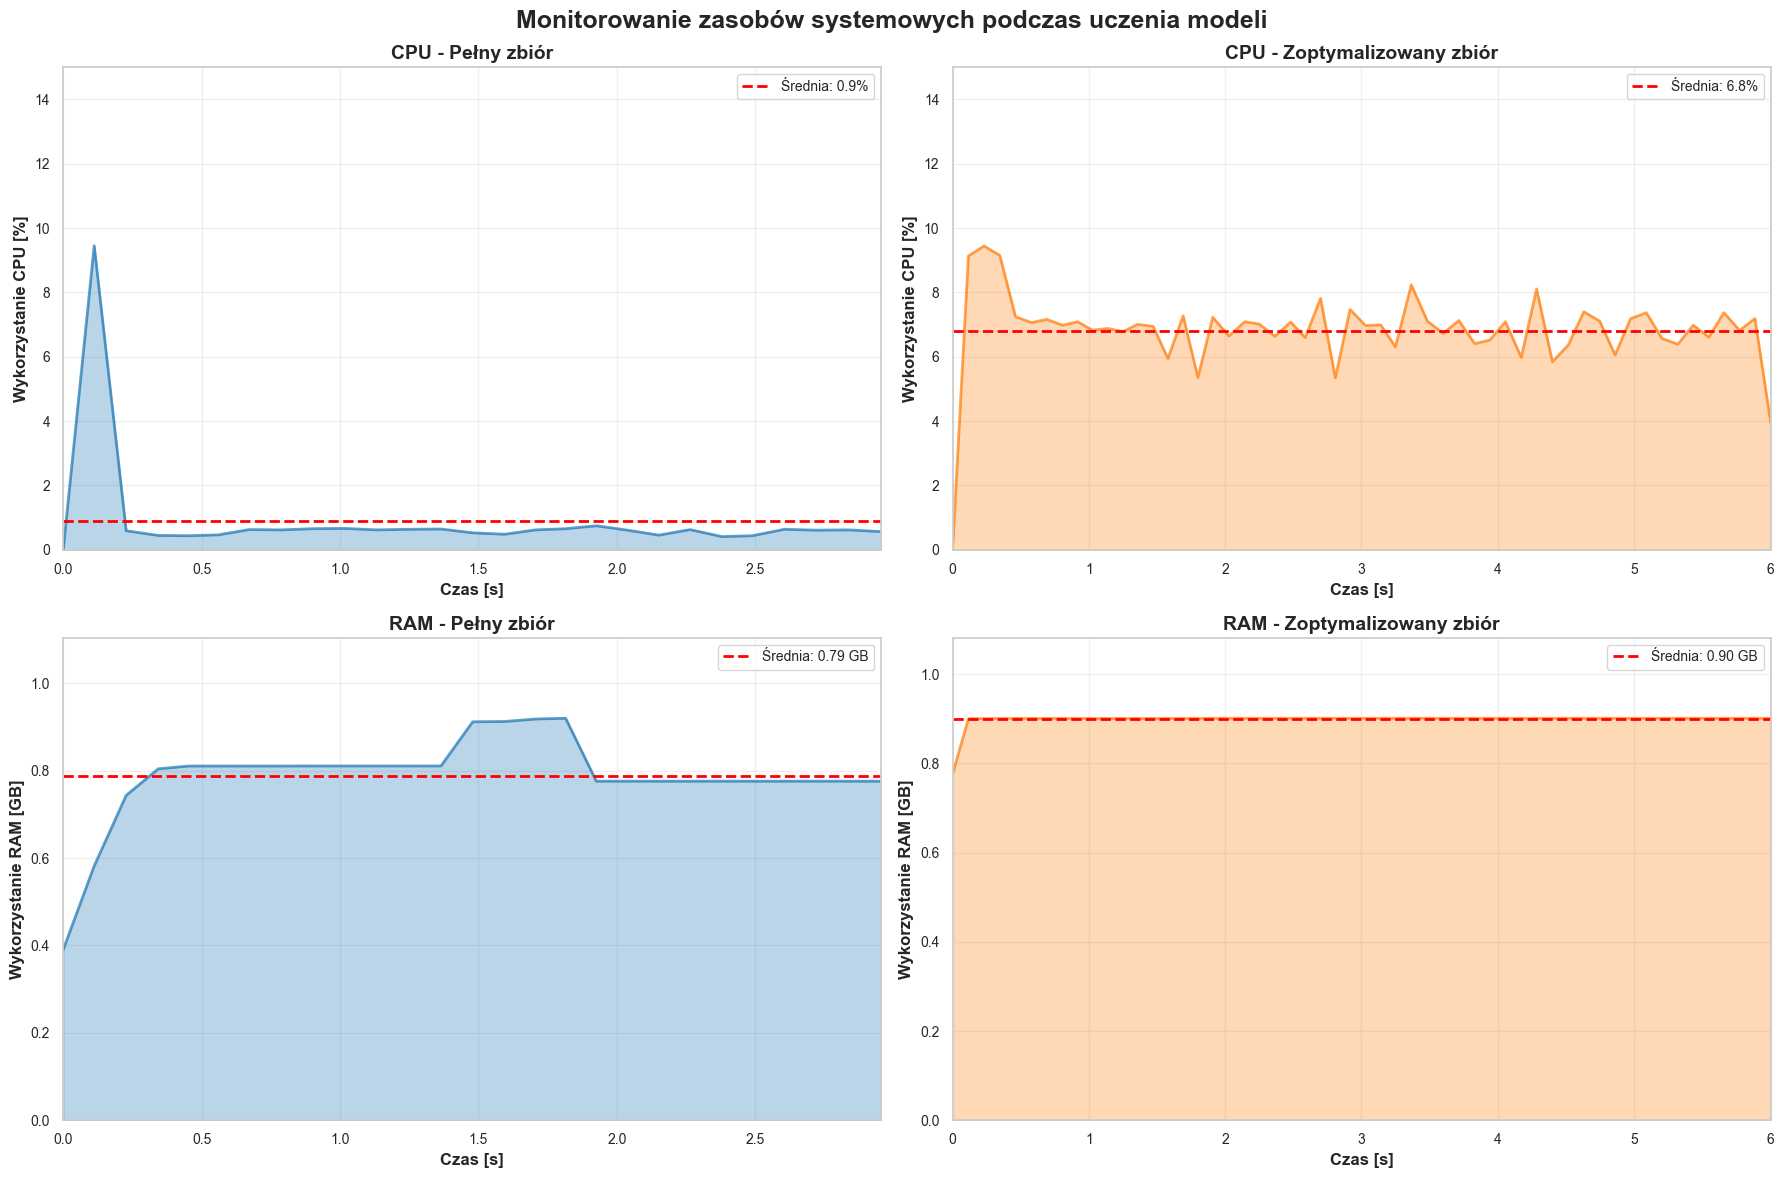

✅ Wizualizacja wykorzystania zasobów zapisana


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Monitorowanie zasobów systemowych podczas uczenia modeli', fontsize=18, fontweight='bold')

dataset_names = list(resource_stats.keys())
colors = ['#1f77b4', '#ff7f0e']

for idx, dataset_name in enumerate(dataset_names):
    monitor = resource_stats[dataset_name]['monitor']
    stats = resource_stats[dataset_name]['stats']

    if stats and len(monitor.timestamps) > 0:
        time_array = np.array(monitor.timestamps)
        time_array = time_array - time_array[0]
        cpu_array = np.array(monitor.cpu_percent)
        ram_array = np.array(monitor.ram_gb)

        axes[0, idx].plot(time_array, cpu_array, color=colors[idx], linewidth=2, alpha=0.7)
        axes[0, idx].axhline(y=stats['cpu']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["cpu"]["mean"]:.1f}%')
        axes[0, idx].fill_between(time_array, cpu_array, alpha=0.3, color=colors[idx])
        axes[0, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[0, idx].set_ylabel('Wykorzystanie CPU [%]', fontsize=12, fontweight='bold')
        axes[0, idx].set_title(f'CPU - {dataset_name}', fontweight='bold', fontsize=14)
        axes[0, idx].legend(fontsize=10)
        axes[0, idx].grid(True, alpha=0.3)
        axes[0, idx].set_xlim([0, time_array[-1]])
        axes[0, idx].set_ylim([0, max(15, stats['cpu']['max'] * 1.1)])

        axes[1, idx].plot(time_array, ram_array, color=colors[idx], linewidth=2, alpha=0.7)
        axes[1, idx].axhline(y=stats['ram']['mean'], color='red', linestyle='--',
                            linewidth=2, label=f'Średnia: {stats["ram"]["mean"]:.2f} GB')
        axes[1, idx].fill_between(time_array, ram_array, alpha=0.3, color=colors[idx])
        axes[1, idx].set_xlabel('Czas [s]', fontsize=12, fontweight='bold')
        axes[1, idx].set_ylabel('Wykorzystanie RAM [GB]', fontsize=12, fontweight='bold')
        axes[1, idx].set_title(f'RAM - {dataset_name}', fontweight='bold', fontsize=14)
        axes[1, idx].legend(fontsize=10)
        axes[1, idx].grid(True, alpha=0.3)
        axes[1, idx].set_xlim([0, time_array[-1]])
        axes[1, idx].set_ylim([0, stats['ram']['max'] * 1.2])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_resource_usage.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja wykorzystania zasobów zapisana")

## 6. Ewaluacja modelu


In [8]:
evaluation_results = {}

for dataset_name, model_data in trained_models.items():
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = model_data['model']
    data = train_test_data[dataset_name]

    X_test_scaled = data['X_test_scaled']
    y_test = data['y_test']
    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']

    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja (Precision): {precision:.4f}")
    print(f"  • Czułość (Recall): {recall:.4f}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")


EWALUACJA MODELU - PEŁNY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9314
  • Precyzja (Precision): 0.8901
  • Czułość (Recall): 0.9145
  • Miara F1 (F1-Score): 0.9022
  • AUC-ROC: 0.9792

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,908
  • Fałszywie pozytywne (FP): 692
  • Fałszywie negatywne (FN): 524
  • Prawdziwie pozytywne (TP): 5,606

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9793 ± 0.0008
  • Min: 0.9779
  • Max: 0.9802

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR

WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9327
  • Precyzja (Precision): 0.8957
  • Czułość (Recall): 0.9141
  • Miara F1 (F1-Score): 0.9048
  • AUC-ROC: 0.9789

MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,694
  • Fałszywie pozytywne (FP): 649
  • Fałszywie negatywne (FN): 524
  • Prawdziwie pozytywne (TP): 5,575

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9787 ± 0.0009
  • Min: 0.9770
  • Max: 0.9797

PORÓWNANIE WYNIKÓW
Metryka       

## 7. Wizualizacja kompleksowa i analiza


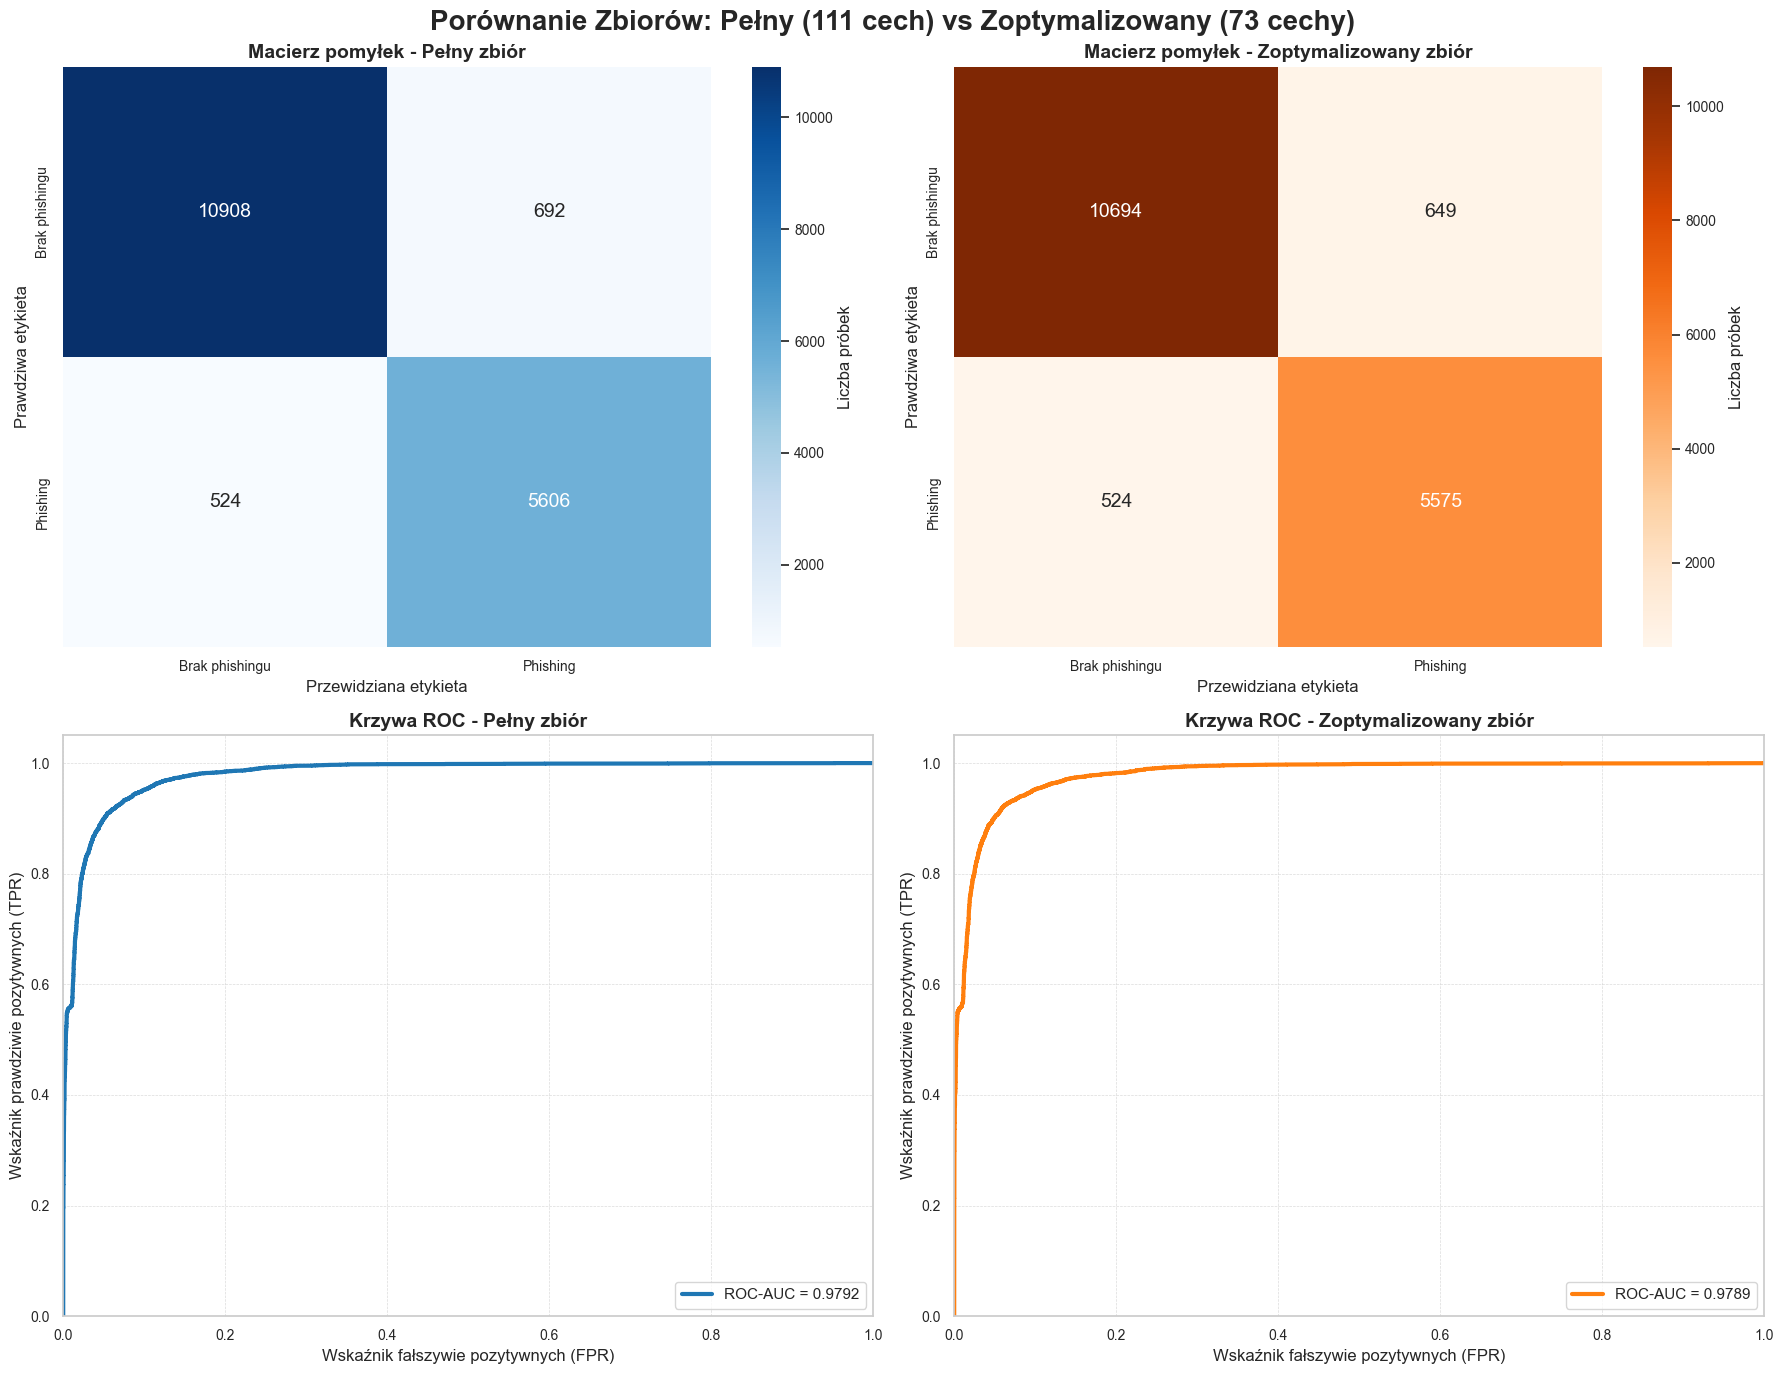

✅ Wizualizacja porównawcza zapisana


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Porównanie Zbiorów: Pełny (111 cech) vs Zoptymalizowany (73 cechy)', fontsize=20, fontweight='bold')

dataset_names = list(trained_models.keys())
colors = ['#1f77b4', '#ff7f0e']

for idx, dataset_name in enumerate(dataset_names):
    cm = evaluation_results[dataset_name]['confusion_matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues' if idx == 0 else 'Oranges',
                xticklabels=['Brak phishingu', 'Phishing'],
                yticklabels=['Brak phishingu', 'Phishing'],
                ax=axes[0, idx], annot_kws={"size": 14}, cbar_kws={'label': 'Liczba próbek'})
    axes[0, idx].set_title(f'Macierz pomyłek - {dataset_name}', fontweight='bold', fontsize=14)
    axes[0, idx].set_ylabel('Prawdziwa etykieta')
    axes[0, idx].set_xlabel('Przewidziana etykieta')

for idx, dataset_name in enumerate(dataset_names):
    y_test = train_test_data[dataset_name]['y_test']
    y_pred_proba = evaluation_results[dataset_name]['y_pred_proba']
    auc_roc = evaluation_results[dataset_name]['auc_roc']

    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    axes[1, idx].plot(fpr, tpr, color=colors[idx], lw=3, label=f'ROC-AUC = {auc_roc:.4f}')
    axes[1, idx].set_xlim([0.0, 1.0])
    axes[1, idx].set_ylim([0.0, 1.05])
    axes[1, idx].set_xlabel('Wskaźnik fałszywie pozytywnych (FPR)', fontsize=12)
    axes[1, idx].set_ylabel('Wskaźnik prawdziwie pozytywnych (TPR)', fontsize=12)
    axes[1, idx].set_title(f'Krzywa ROC - {dataset_name}', fontweight='bold', fontsize=14)
    axes[1, idx].legend(loc="lower right", fontsize=11)
    axes[1, idx].grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.7)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja porównawcza zapisana")

## 7.1. Porównanie metryk w postaci wykresów słupkowych


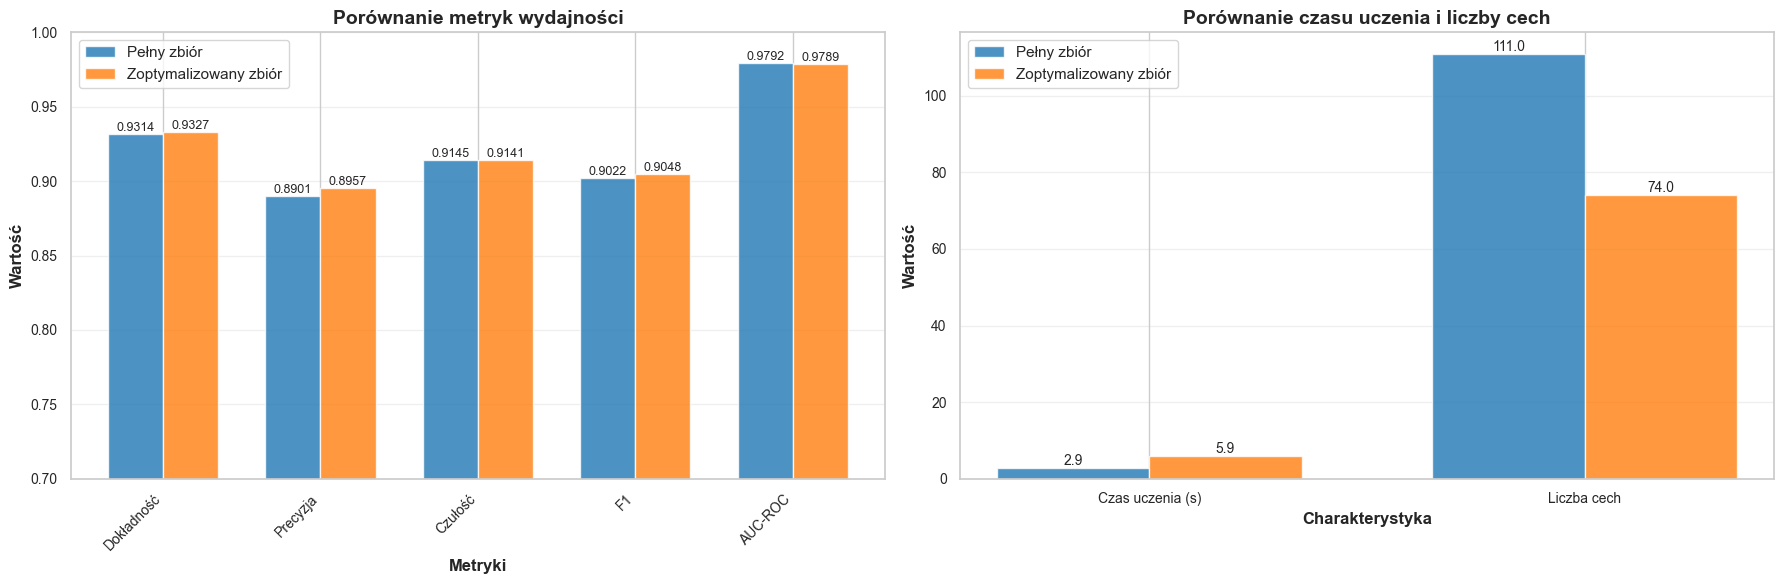

✅ Wizualizacja metryk zapisana


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

metrics = ['Dokładność', 'Precyzja', 'Czułość', 'F1', 'AUC-ROC']
metric_keys = ['accuracy', 'precision', 'recall', 'f1', 'auc_roc']
full_values = [evaluation_results['Pełny zbiór'][key] for key in metric_keys]
opt_values = [evaluation_results['Zoptymalizowany zbiór'][key] for key in metric_keys]

x = np.arange(len(metrics))
width = 0.35

bars1 = axes[0].bar(x - width/2, full_values, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[0].bar(x + width/2, opt_values, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[0].set_xlabel('Metryki', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[0].set_title('Porównanie metryk wydajności', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=45, ha='right')
axes[0].legend(fontsize=11)
axes[0].set_ylim([0.7, 1.0])
axes[0].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.4f}',
                    ha='center', va='bottom', fontsize=9)

labels = ['Czas uczenia (s)', 'Liczba cech']
full_stats = [
    trained_models['Pełny zbiór']['training_time'],
    data_splits['Pełny zbiór']['feature_count']
]
opt_stats = [
    trained_models['Zoptymalizowany zbiór']['training_time'],
    data_splits['Zoptymalizowany zbiór']['feature_count']
]

x_pos = np.arange(len(labels))
bars1 = axes[1].bar(x_pos - width/2, full_stats, width, label='Pełny zbiór', color='#1f77b4', alpha=0.8)
bars2 = axes[1].bar(x_pos + width/2, opt_stats, width, label='Zoptymalizowany zbiór', color='#ff7f0e', alpha=0.8)

axes[1].set_xlabel('Charakterystyka', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Wartość', fontsize=12, fontweight='bold')
axes[1].set_title('Porównanie czasu uczenia i liczby cech', fontsize=14, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(labels)
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[1].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}',
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja metryk zapisana")

## 7.1b. Ścieżka decyzyjna dla przykładowego URL


ANALIZA ŚCIEŻKI DECYZYJNEJ DLA PRZYKŁADOWYCH URL-I

URL #45129 - Prawdziwa etykieta: Phishing
Predykcja modelu: Phishing
Prawdopodobieństwo:
  • Brak phishingu: 0.0062 (0.62%)
  • Phishing: 0.9938 (99.38%)

Wszystkie cechy dla tego URL (indeks #45129):
  • URL: Liczba "." w całym URL                       : 2.0000
  • URL: Liczba "-" w całym URL                       : 0.0000
  • URL: Liczba "_" w całym URL                       : 1.0000
  • URL: Liczba "/" w całym URL                       : 2.0000
  • URL: Liczba "?" w całym URL                       : 0.0000
  • URL: Liczba "=" w całym URL                       : 0.0000
  • URL: Liczba "@" w całym URL                       : 0.0000
  • URL: Liczba "&" w całym URL                       : 0.0000
  • URL: Długość Top Level Domain                     : 1.0000
  • URL: Całkowita długość                            : 53.0000
  • Domena: Liczba "."                                : 1.0000
  • Domena: Liczba "-"                               

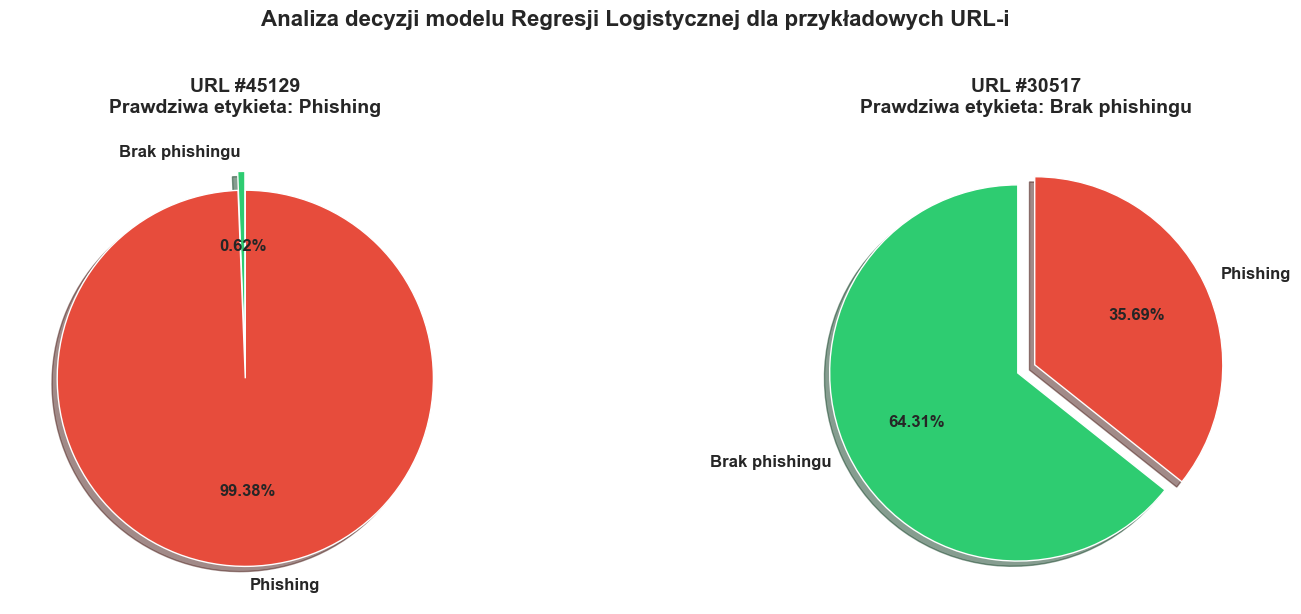


✅ Wizualizacja decyzji dla przykładowych URL-i zapisana


In [11]:
dataset_name = 'Zoptymalizowany zbiór'
model = trained_models[dataset_name]['model']
data = train_test_data[dataset_name]
X_test = data['X_test']
X_test_scaled = data['X_test_scaled']
y_test = data['y_test']

phishing_idx = y_test[y_test == 1].index[0]
safe_idx = y_test[y_test == 0].index[0]

examples = [
    {'idx': phishing_idx, 'label': 'Phishing', 'color': '#ff7f0e'},
    {'idx': safe_idx, 'label': 'Brak phishingu', 'color': '#1f77b4'}
]

print("="*80)
print("ANALIZA ŚCIEŻKI DECYZYJNEJ DLA PRZYKŁADOWYCH URL-I")
print("="*80)

def create_example_url_from_features(feature_dict):
    """
    Tworzy przykładowy URL na podstawie wartości cech
    """
    length_url = int(feature_dict.get('length_url', 50))
    qty_hyphen_url = int(feature_dict.get('qty_hyphen_url', 0))
    qty_slash_url = int(feature_dict.get('qty_slash_url', 3))
    qty_questionmark_url = int(feature_dict.get('qty_questionmark_url', 0))
    qty_equal_url = int(feature_dict.get('qty_equal_url', 0))
    domain_length = int(feature_dict.get('domain_length', 15))

    protocol = "https://"

    domain_base = "example"
    if qty_hyphen_url > 0:
        domain_base = "ex-ample"

    tld = ".com"

    domain = domain_base + tld

    path_length = max(0, length_url - len(protocol) - domain_length - 10)
    if qty_slash_url > 3:
        path = "/page/" + "sub/" * (qty_slash_url - 4) + "file.html"
    else:
        path = "/page/file.html"

    params = ""
    if qty_questionmark_url > 0:
        params = "?id=123"
        if qty_equal_url > 1:
            params += "&param=value"

    example_url = protocol + domain + path + params

    return example_url

for example in examples:
    idx = example['idx']
    true_label = example['label']
    sample_scaled = X_test_scaled[X_test.index.get_loc(idx):X_test.index.get_loc(idx)+1]
    sample = X_test.loc[idx:idx]

    prediction = model.predict(sample_scaled)[0]
    prediction_proba = model.predict_proba(sample_scaled)[0]
    predicted_label = 'Phishing' if prediction == 1 else 'Brak phishingu'

    print(f"\n{'='*80}")
    print(f"URL #{idx} - Prawdziwa etykieta: {true_label}")
    print(f"{'='*80}")
    print(f"Predykcja modelu: {predicted_label}")
    print(f"Prawdopodobieństwo:")
    print(f"  • Brak phishingu: {prediction_proba[0]:.4f} ({prediction_proba[0]*100:.2f}%)")
    print(f"  • Phishing: {prediction_proba[1]:.4f} ({prediction_proba[1]*100:.2f}%)")

    print(f"\nWszystkie cechy dla tego URL (indeks #{idx}):")
    feature_values = sample.iloc[0]
    feature_dict = {}

    for col in X_test.columns:
        readable_name = get_readable_name(col)
        value = feature_values[col]
        feature_dict[col] = value
        print(f"  • {readable_name:50s}: {value:.4f}")

    example_url = create_example_url_from_features(feature_dict)
    print(f"\n{'='*40}")
    print(f"PRZYKŁADOWY URL PASUJĄCY DO STATYSTYK:")
    print(f"{example_url}")
    print(f"{'='*40}")

    print(f"\nTop 10 najważniejszych cech (według współczynnika modelu):")
    feature_names_readable = [get_readable_name(col) for col in X_test.columns]
    coefficients = model.coef_[0]

    sorted_features = sorted(
        zip(feature_names_readable, feature_values, coefficients),
        key=lambda x: abs(x[2]),
        reverse=True
    )[:10]

    for feat_name, feat_val, coef in sorted_features:
        contribution = feat_val * coef
        print(f"  • {feat_name}: wartość={feat_val:.4f}, współczynnik={coef:.4f}, wkład={contribution:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Analiza decyzji modelu Regresji Logistycznej dla przykładowych URL-i',
             fontsize=16, fontweight='bold', y=1.02)

for idx, example in enumerate(examples):
    sample_idx = example['idx']
    label = example['label']
    color = example['color']
    sample_scaled = X_test_scaled[X_test.index.get_loc(sample_idx):X_test.index.get_loc(sample_idx)+1]
    sample = X_test.loc[sample_idx:sample_idx]

    prediction_proba = model.predict_proba(sample_scaled)[0]

    labels_pie = ['Brak phishingu', 'Phishing']
    sizes = [prediction_proba[0] * 100, prediction_proba[1] * 100]
    colors_pie = ['#2ecc71', '#e74c3c']
    explode = (0.05, 0.05)

    axes[idx].pie(sizes, explode=explode, labels=labels_pie, colors=colors_pie,
                  autopct='%1.2f%%', shadow=True, startangle=90,
                  textprops={'fontsize': 12, 'fontweight': 'bold'})
    axes[idx].set_title(f'URL #{sample_idx}\nPrawdziwa etykieta: {label}',
                       fontweight='bold', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_decision_examples.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Wizualizacja decyzji dla przykładowych URL-i zapisana")

## 7.2. Wpływ rozmiaru zbioru uczącego na skuteczność modelu


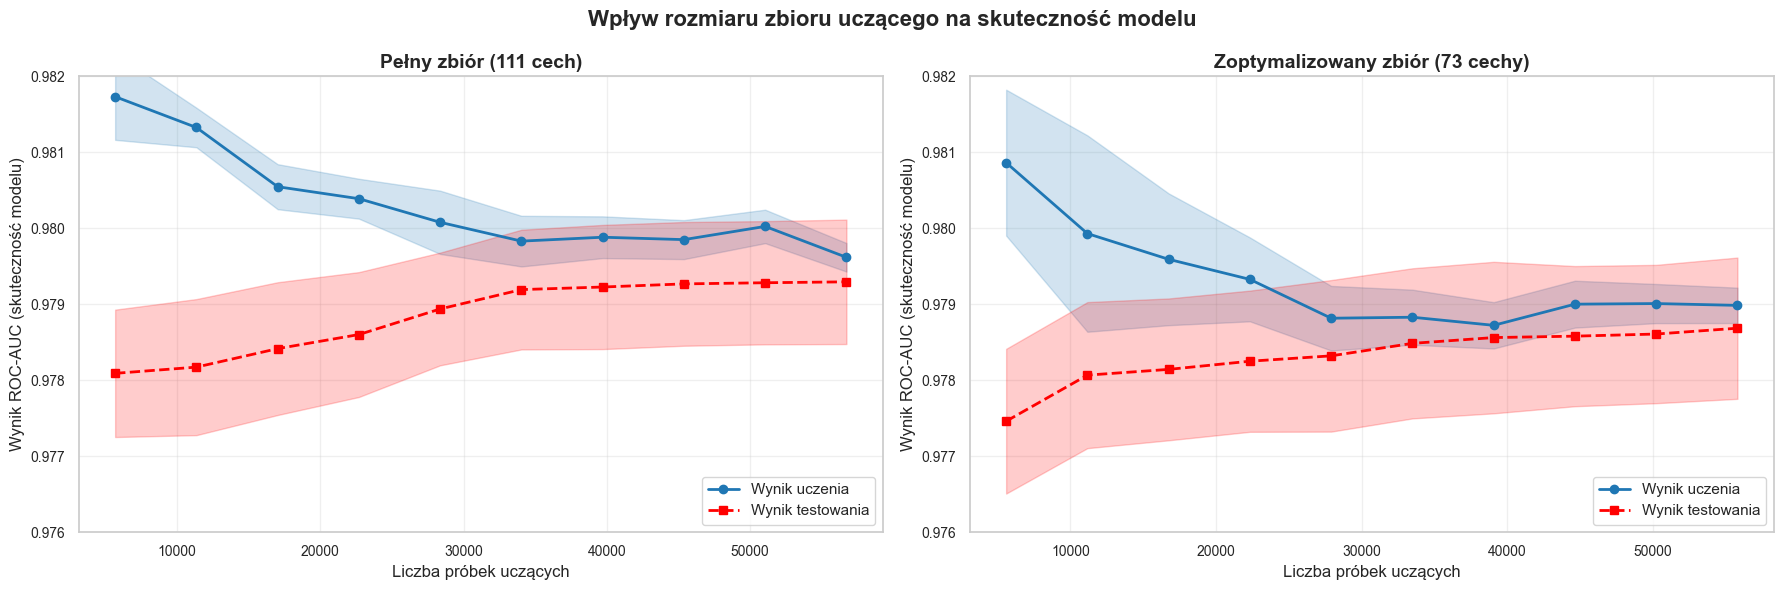

✅ Krzywe uczenia zapisane


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wpływ rozmiaru zbioru uczącego na skuteczność modelu', fontsize=16, fontweight='bold')

dataset_keys = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_names = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']

for idx, (dataset_key, dataset_name) in enumerate(zip(dataset_keys, dataset_names)):
    model = trained_models[dataset_key]['model']
    data = train_test_data[dataset_key]
    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']

    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_scaled, y_train,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10),
        random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[idx].plot(train_sizes, train_mean, label='Wynik uczenia', color='#1f77b4', linewidth=2, marker='o')
    axes[idx].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2, color='#1f77b4')

    axes[idx].plot(train_sizes, val_mean, label='Wynik testowania', color='red', linewidth=2, marker='s', linestyle='--')
    axes[idx].fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2, color='red')

    axes[idx].set_xlabel('Liczba próbek uczących', fontsize=12)
    axes[idx].set_ylabel('Wynik ROC-AUC (skuteczność modelu)', fontsize=12)
    axes[idx].set_title(f'{dataset_name}', fontweight='bold', fontsize=14)
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.976, 0.982])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Krzywe uczenia zapisane")

## 7.3. Wpływ regularyzacji (parametr C) na skuteczność modelu


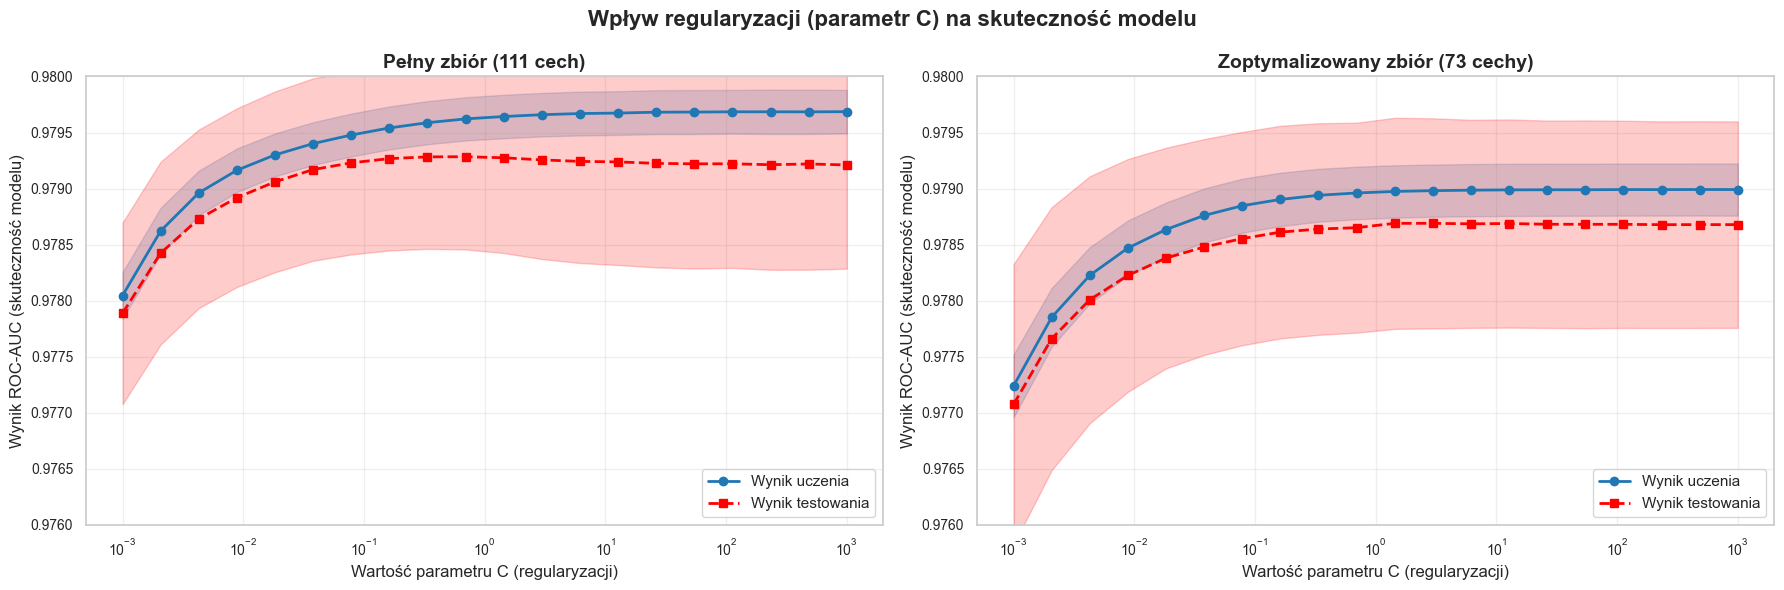

✅ Krzywe walidacyjne zapisane


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Wpływ regularyzacji (parametr C) na skuteczność modelu', fontsize=16, fontweight='bold')

dataset_keys = ['Pełny zbiór', 'Zoptymalizowany zbiór']
dataset_names = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']

param_range = np.logspace(-3, 3, 20)

for idx, (dataset_key, dataset_name) in enumerate(zip(dataset_keys, dataset_names)):
    model_base = LogisticRegression(solver='liblinear', max_iter=1000, random_state=42)
    data = train_test_data[dataset_key]
    X_train_scaled = data['X_train_scaled']
    y_train = data['y_train']

    train_scores, val_scores = validation_curve(
        model_base, X_train_scaled, y_train,
        param_name='C',
        param_range=param_range,
        cv=5,
        scoring='roc_auc',
        n_jobs=-1
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)

    axes[idx].plot(param_range, train_mean, label='Wynik uczenia', color='#1f77b4', linewidth=2, marker='o')
    axes[idx].fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2, color='#1f77b4')

    axes[idx].plot(param_range, val_mean, label='Wynik testowania', color='red', linewidth=2, marker='s', linestyle='--')
    axes[idx].fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.2, color='red')

    axes[idx].set_xlabel('Wartość parametru C (regularyzacji)', fontsize=12)
    axes[idx].set_ylabel('Wynik ROC-AUC (skuteczność modelu)', fontsize=12)
    axes[idx].set_title(f'{dataset_name}', fontweight='bold', fontsize=14)
    axes[idx].set_xscale('log')
    axes[idx].legend(loc='lower right', fontsize=11)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim([0.976, 0.980])

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_validation_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Krzywe walidacyjne zapisane")

## 7.4. Tabela porównawcza wyników


In [14]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Średnia CV AUC': [evaluation_results['Pełny zbiór']['cv_mean'], evaluation_results['Zoptymalizowany zbiór']['cv_mean']],
    'Odchylenie CV AUC': [evaluation_results['Pełny zbiór']['cv_std'], evaluation_results['Zoptymalizowany zbiór']['cv_std']],
    'Czas uczenia (s)': [trained_models['Pełny zbiór']['training_time'], trained_models['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [data_splits['Pełny zbiór']['feature_count'], data_splits['Zoptymalizowany zbiór']['feature_count']]
})

comparison_df.to_csv('../data/logistic_regression_comparison.csv', index=False)
print(f"✓ Porównanie zapisane: ../data/logistic_regression_comparison.csv")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

✓ Porównanie zapisane: ../data/logistic_regression_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  Miara F1  AUC-ROC  Średnia CV AUC  Odchylenie CV AUC  Czas uczenia (s)  Liczba cech
          Pełny zbiór    0.931416  0.890124 0.914519  0.902156 0.979246        0.979291           0.000821          2.938472          111
Zoptymalizowany zbiór    0.932749  0.895726 0.914084  0.904812 0.978944        0.978686           0.000930          5.945195           74


## 7.5. Ważność cech w obu modelach


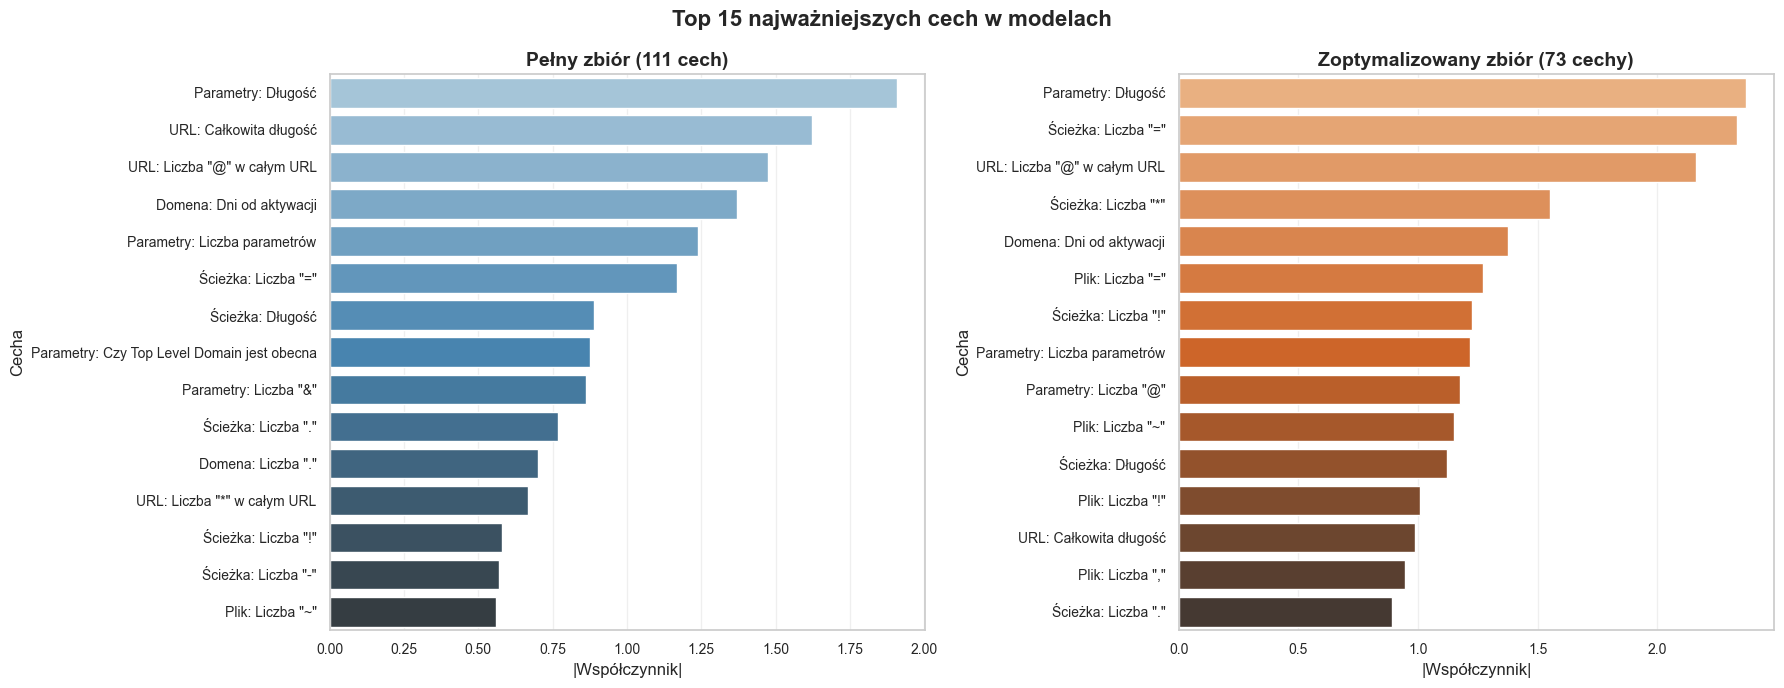

✅ Wizualizacja ważności cech zapisana


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Top 15 najważniejszych cech w modelach', fontsize=16, fontweight='bold')

dataset_names = list(trained_models.keys())
dataset_display = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']
colors_palette = ['Blues_d', 'Oranges_d']

for idx, dataset_name in enumerate(dataset_names):
    model = trained_models[dataset_name]['model']
    data = train_test_data[dataset_name]
    X = data['X_train']

    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in X.columns],
        'Współczynnik': np.abs(model.coef_[0])
    }).sort_values('Współczynnik', ascending=False)

    top_features = feature_importance.head(15)

    sns.barplot(x='Współczynnik', y='Cecha', data=top_features,
                palette=colors_palette[idx], ax=axes[idx])
    axes[idx].set_xlabel('|Współczynnik|', fontsize=12)
    axes[idx].set_ylabel('Cecha', fontsize=12)
    axes[idx].set_title(f'{dataset_display[idx]}', fontweight='bold', fontsize=14)
    axes[idx].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/logistic_regression_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Wizualizacja ważności cech zapisana")

## 7.6. Wizualizacja architektury regresji logistycznej


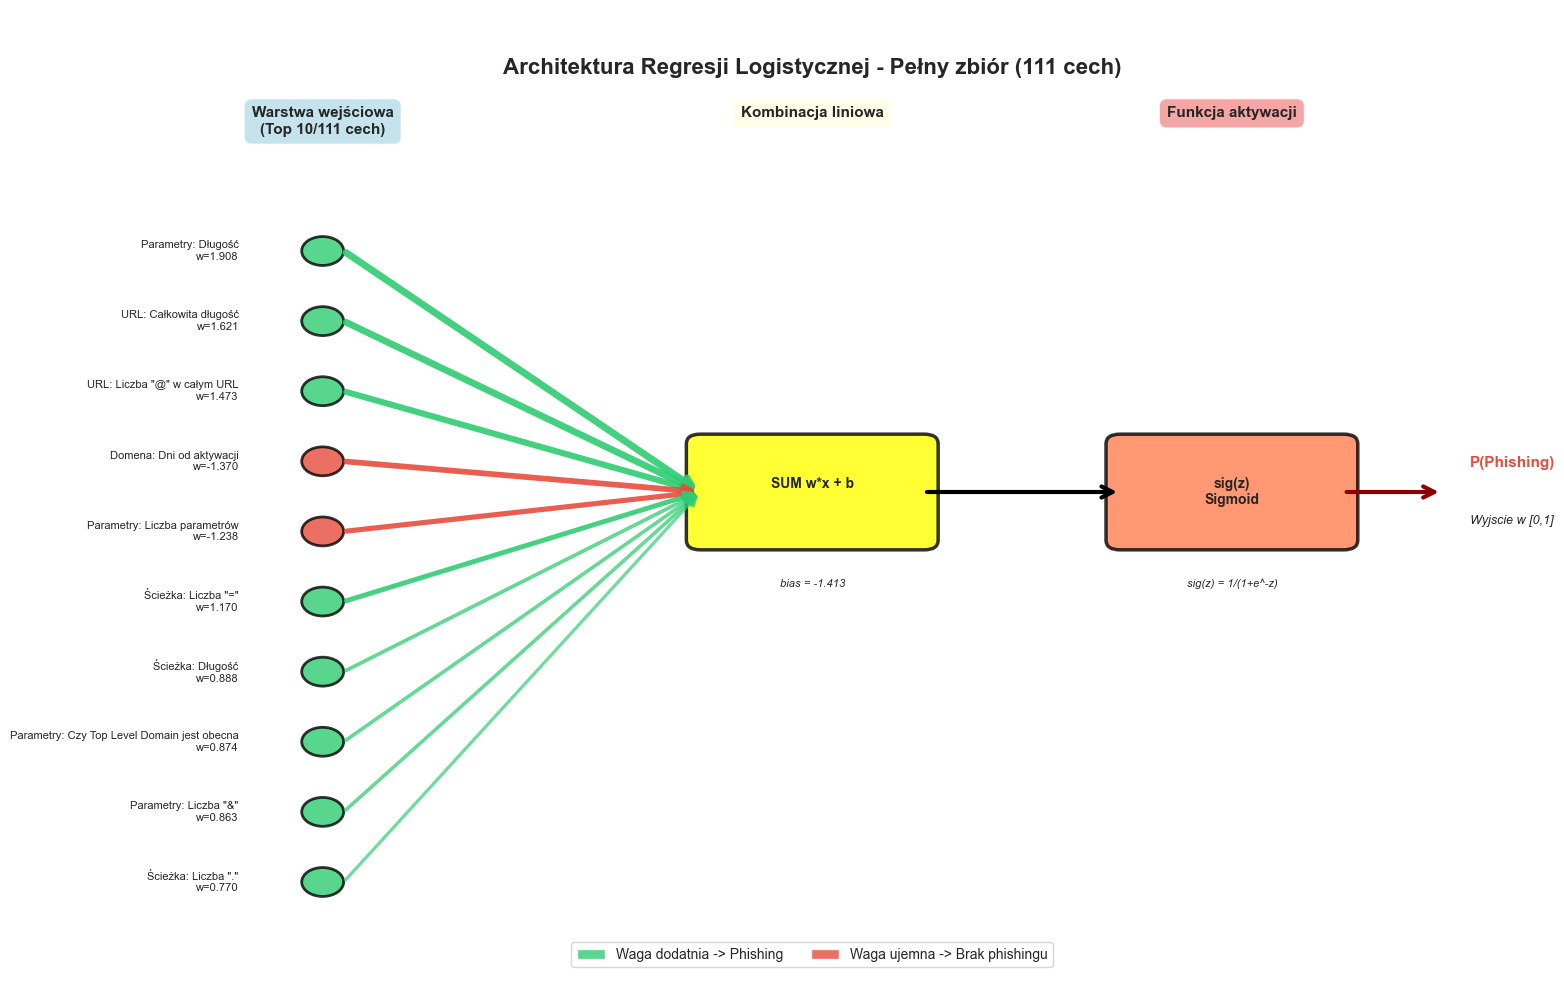

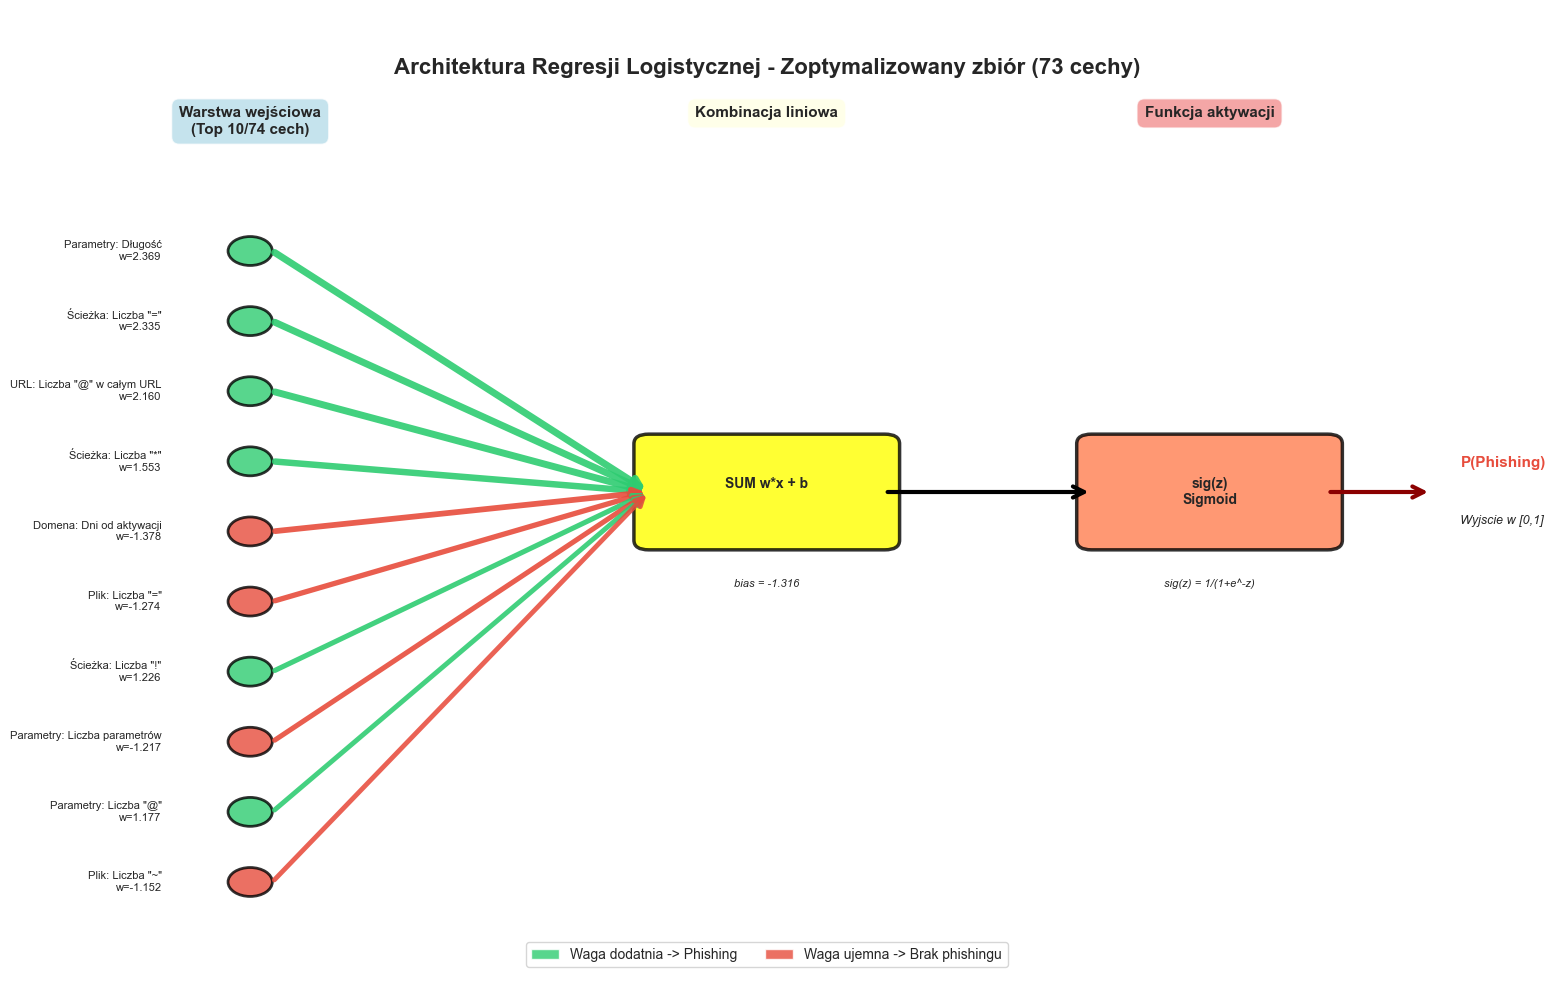

✅ Wizualizacja architektury modelu zapisana


In [16]:
dataset_names = list(trained_models.keys())
dataset_display = ['Pełny zbiór (111 cech)', 'Zoptymalizowany zbiór (73 cechy)']

for idx, dataset_name in enumerate(dataset_names):
    model = trained_models[dataset_name]['model']
    data = train_test_data[dataset_name]
    total_features = len(data['X_train'].columns)

    fig, ax = plt.subplots(figsize=(16, 10))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    feature_weights = pd.DataFrame({
        'Cecha': [get_readable_name(col) for col in data['X_train'].columns],
        'Waga': model.coef_[0]
    }).sort_values('Waga', key=abs, ascending=False)

    top_n = 10
    top_features = feature_weights.head(top_n)

    input_layer_x = 1.5
    input_spacing = 8 / (top_n + 1)

    ax.text(5, 9.5, f'Architektura Regresji Logistycznej - {dataset_display[idx]}',
            ha='center', va='top', fontsize=16, fontweight='bold')

    ax.text(input_layer_x, 9, f'Warstwa wejściowa\n(Top {top_n}/{total_features} cech)',
            ha='center', va='top', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='lightblue', alpha=0.7))

    input_nodes = []
    for i, (_, row) in enumerate(top_features.iterrows()):
        y_pos = 7.5 - i * input_spacing
        weight = row['Waga']
        color = '#2ecc71' if weight > 0 else '#e74c3c'

        circle = Circle((input_layer_x, y_pos), 0.15,
                       facecolor=color, edgecolor='black', linewidth=2, alpha=0.8)
        ax.add_patch(circle)
        input_nodes.append((input_layer_x, y_pos, weight))

        feature_text = f"{row['Cecha']}\nw={weight:.3f}"
        ax.text(input_layer_x - 0.6, y_pos, feature_text,
               ha='right', va='center', fontsize=8)

    linear_x = 5
    linear_y = 5

    ax.text(linear_x, 9, 'Kombinacja liniowa', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='lightyellow', alpha=0.7))

    sum_box = FancyBboxPatch((linear_x - 0.8, linear_y - 0.5), 1.6, 1,
                            boxstyle="round,pad=0.1",
                            facecolor='yellow', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(sum_box)

    ax.text(linear_x, linear_y, 'SUM w*x + b\n', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(linear_x, linear_y - 0.9, f'bias = {model.intercept_[0]:.3f}',
           ha='center', va='top', fontsize=8, style='italic')

    for inp_x, inp_y, weight in input_nodes:
        linewidth = min(abs(weight) * 3, 5)
        color = '#2ecc71' if weight > 0 else '#e74c3c'
        alpha = min(abs(weight) * 0.5 + 0.3, 0.9)

        arrow = FancyArrowPatch((inp_x + 0.15, inp_y), (linear_x - 0.8, linear_y),
                               arrowstyle='->', mutation_scale=15,
                               color=color, linewidth=linewidth, alpha=alpha)
        ax.add_patch(arrow)

    sigmoid_x = 8
    sigmoid_y = 5

    ax.text(sigmoid_x, 9, 'Funkcja aktywacji', ha='center', va='top',
           fontsize=11, fontweight='bold', bbox=dict(boxstyle='round,pad=0.5',
           facecolor='lightcoral', alpha=0.7))

    sigmoid_box = FancyBboxPatch((sigmoid_x - 0.8, sigmoid_y - 0.5), 1.6, 1,
                                boxstyle="round,pad=0.1",
                                facecolor='coral', edgecolor='black', linewidth=2.5, alpha=0.8)
    ax.add_patch(sigmoid_box)

    ax.text(sigmoid_x, sigmoid_y, 'sig(z)\nSigmoid', ha='center', va='center',
           fontsize=10, fontweight='bold')
    ax.text(sigmoid_x, sigmoid_y - 0.9, 'sig(z) = 1/(1+e^-z)',
           ha='center', va='top', fontsize=8, style='italic')

    arrow = FancyArrowPatch((linear_x + 0.8, linear_y), (sigmoid_x - 0.8, sigmoid_y),
                           arrowstyle='->', mutation_scale=20,
                           color='black', linewidth=3)
    ax.add_patch(arrow)

    output_y = 5
    output_x = sigmoid_x + 1.2

    ax.text(output_x + 0.5, output_y + 0.3, 'P(Phishing)', ha='left', va='center',
           fontsize=11, fontweight='bold', color='#e74c3c')
    ax.text(output_x + 0.5, output_y - 0.3, 'Wyjscie w [0,1]', ha='left', va='center',
           fontsize=9, style='italic')

    arrow = FancyArrowPatch((sigmoid_x + 0.8, sigmoid_y), (output_x + 0.3, output_y),
                           arrowstyle='->', mutation_scale=20,
                           color='darkred', linewidth=3)
    ax.add_patch(arrow)

    legend_elements = [
        mpatches.Patch(facecolor='#2ecc71', alpha=0.8, label='Waga dodatnia -> Phishing'),
        mpatches.Patch(facecolor='#e74c3c', alpha=0.8, label='Waga ujemna -> Brak phishingu'),
    ]
    ax.legend(handles=legend_elements, loc='lower center', fontsize=10, ncol=2)

    plt.tight_layout()
    plt.savefig(f'{PLOTS_DIR}/logistic_regression_architecture_{dataset_name.replace(" ", "_")}.png',
                dpi=300, bbox_inches='tight')
    plt.show()

print("✅ Wizualizacja architektury modelu zapisana")


## 8. Zapis modeli


In [17]:
for dataset_name, model_data in trained_models.items():
    model = model_data['model']
    scaler = train_test_data[dataset_name]['scaler']

    if 'Pełny' in dataset_name:
        model_filename = f'{MODELS_DIR}/logistic_regression_full.pkl'
        scaler_filename = f'{MODELS_DIR}/logistic_regression_scaler_full.pkl'
    else:
        model_filename = f'{MODELS_DIR}/logistic_regression_optimized.pkl'
        scaler_filename = f'{MODELS_DIR}/logistic_regression_scaler_optimized.pkl'

    with open(model_filename, 'wb') as f:
        pickle.dump(model, f)

    with open(scaler_filename, 'wb') as f:
        pickle.dump(scaler, f)

    print(f"✅ {dataset_name}:")
    print(f"   Model zapisany: {model_filename}")
    print(f"   Skaler zapisany: {scaler_filename}")
    print(f"   Parametry: {model_data['params']}")
    print(f"   ROC-AUC: {model_data['cv_score']:.4f}")
    print(f"   Test ROC-AUC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print()

print("="*80)
print("PODSUMOWANIE KOŃCOWE")
print("="*80)
print(f"\nPrzeszkolono i zapisano {len(trained_models)} modele regresji logistycznej:")
print(f"  1. Model na pełnym zbiorze: {data_splits['Pełny zbiór']['feature_count']} cech")
print(f"  2. Model na zoptymalizowanym zbiorze: {data_splits['Zoptymalizowany zbiór']['feature_count']} cech")
print(f"\nWizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")


✅ Pełny zbiór:
   Model zapisany: ../models/logistic_regression/logistic_regression_full.pkl
   Skaler zapisany: ../models/logistic_regression/logistic_regression_scaler_full.pkl
   Parametry: {'C': 1, 'max_iter': 1000, 'solver': 'lbfgs'}
   ROC-AUC: 0.9793
   Test ROC-AUC: 0.9792

✅ Zoptymalizowany zbiór:
   Model zapisany: ../models/logistic_regression/logistic_regression_optimized.pkl
   Skaler zapisany: ../models/logistic_regression/logistic_regression_scaler_optimized.pkl
   Parametry: {'C': 10, 'max_iter': 1000, 'solver': 'liblinear'}
   ROC-AUC: 0.9787
   Test ROC-AUC: 0.9789

PODSUMOWANIE KOŃCOWE

Przeszkolono i zapisano 2 modele regresji logistycznej:
  1. Model na pełnym zbiorze: 111 cech
  2. Model na zoptymalizowanym zbiorze: 74 cech

Wizualizacje zapisane w: ../static/plots/logistic_regression/
Modele zapisane w: ../models/logistic_regression/
